# Семинар 5. Pandas: повторение основных методов

**Pandas** — главная библиотека Python для работы с таблицами. Это как Excel, только внутри Python: таблицу можно загрузить, отфильтровать, отсортировать, посчитать средние и сгруппировать — каждое действие одной строкой кода.

Во втором семинаре мы анализировали отзывы о банках с помощью списков и циклов: чтобы посчитать среднюю оценку по городу, приходилось писать по 5–10 строк. Сегодня увидим, что в pandas то же самое делается в одну строку.

**Данные:** 20 000 отзывов об организациях с Яндекс Карт за 2023 год — магазины, кафе, гостиницы, банки, салоны красоты по всей России. Это выборка из открытого датасета Яндекса.

### План
1. Загружаем таблицу
2. Первый взгляд на данные
3. Столбцы и простая статистика
4. Фильтрация: выбираем нужные строки
5. Сортировка
6. Чистим данные
7. Новые столбцы и работа с текстом
8. Группировка: сравниваем бренды и города
9. График
10. Сохраняем результат

---
# 1. Загружаем таблицу

Подключаем pandas. По традиции его называют коротким именем `pd` — так пишут во всех учебниках и примерах в интернете.

In [1]:
import pandas as pd

Скачиваем датасет из учебника — так же, как отзывы о банках во втором семинаре:

In [2]:
!wget -q https://raw.githubusercontent.com/nastasyaorlova/nlp-textbook/main/data/geo_reviews_sample.csv

Во втором семинаре мы открывали файл через `open`, читали строки и резали каждую через `split(";")`. В pandas всё это делает одна команда `pd.read_csv`:

In [3]:
df = pd.read_csv("geo_reviews_sample.csv")

Таблица в pandas называется **DataFrame** («датафрейм»). Поэтому переменную с таблицей принято называть `df`. Это обычное имя переменной — его можно заменить любым другим.

💡 Наш файл разделён запятыми — это стандарт CSV, поэтому `read_csv` понимает его сам. Если столбцы разделены точкой с запятой, как в отзывах о банках, нужно указать разделитель: `pd.read_csv("файл.csv", sep=";")`.

---
# 2. Первый взгляд на данные

Первое, что делают с любой новой таблицей, — смотрят на неё. `head()` показывает первые 5 строк:

In [4]:
df.head()

,address,name_ru,rating,rubrics,text
0,"Москва, Новопетровская улица, 16",Продукты,4.0,Магазин продуктов,"Неплохой магазин , есть фрукты, мясо и полуфаб..."
1,"Московская область, городской округ Пушкинский...",Акварель,5.0,Торговый центр,"Парковка удобная, есть на 1м этаже в самом ТЦ ..."
2,"Псков, ул. Техническая / ул. Алексея Алёхина",Сити,5.0,Жилой комплекс,"Все нравится, кроме качества воды. Планировка ..."
3,"Тверь, проспект Победы, 3",Happy burger,5.0,Кафе;Быстрое питание,"Туалет бесплатный, еду не пробовали, целью был..."
4,"Ярославль, улица Кирова, 10/25",ЖаRим в КайF,4.0,Быстрое питание;Кафе;Ресторан,"Бургеры потрясающие, коктейли отличные, но над..."


Столбцы таблицы:

| Столбец | Что внутри |
|---|---|
| `address` | адрес организации |
| `name_ru` | название организации |
| `rating` | оценка от 1 до 5 |
| `rubrics` | тип организации: кафе, гостиница, магазин… Если типов несколько, они перечислены через `;` |
| `text` | текст отзыва |

Слева — номера строк (их называют **индексом**). Как и в списках, нумерация начинается с 0.

Обратите внимание: мы написали просто `df.head()` без `print` — Colab сам красиво показывает таблицу, если она стоит в последней строке ячейки.

Ещё несколько команд для знакомства с таблицей:

In [5]:
print(df.shape)       # размер таблицы: (строк, столбцов)
print(df.columns)     # названия столбцов

(20000, 5)
Index(['address', 'name_ru', 'rating', 'rubrics', 'text'], dtype='str')


`df.shape` — без скобок на конце: это не команда, а **свойство** таблицы, её размер. 20 000 строк — 20 000 отзывов, 5 столбцов.

`info()` — краткая сводка: сколько в каждом столбце заполненных значений и какого они типа:

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   address  20000 non-null  str    
 1   name_ru  19964 non-null  str    
 2   rating   20000 non-null  float64
 3   rubrics  20000 non-null  str    
 4   text     20000 non-null  str    
dtypes: float64(1), str(4)
memory usage: 781.4 KB


Как читать сводку:
- `Non-Null Count` — сколько **заполненных** значений. У `name_ru` их меньше 20 000 — значит, у части отзывов не указано название организации. Это **пропуски**, займёмся ими в разделе 6.
- `Dtype` — тип данных: `float64` — число (с дробной частью), `object` или `str` — текст.

И ещё один способ посмотреть на данные — несколько **случайных** строк. Первые строки бывают нетипичными, поэтому полезно заглянуть в разные места таблицы:

In [7]:
df.sample(5)

,address,name_ru,rating,rubrics,text
13706,"Пермь, улица Куйбышева, 109А",Мужскими руками,5.0,Салон красоты;Салон бровей и ресниц,"Замечательный салон, внимательный персонал, оч..."
155,"Краснодарский край, Анапа, Пионерский проспект 25",У мангала,5.0,Доставка еды и обедов;Кафе,"Вкусный шашлык и креветки, отличная музыка\n\n"
2476,"Воронеж, Кольцовская улица, 23А",KDL,5.0,Медицинская лаборатория,Хочу выразить благодарность сотруднице офиса н...
14019,"Ставропольский край, Ессентуки, улица Ленина, 9",Дача М.И. Пушнова,5.0,Достопримечательность,Стиль 70-х! Хорошая мебель и удобные кровати и...
12738,"Краснодарский край, городской округ Сочи, село...",Главная канатная дорога Курорта Красная Поляна,5.0,"Канатная дорога, фуникулёр",Все понравилось. Кофе и кафе есть во всех этап...


---
# 3. Столбцы и простая статистика

## 3.1. Как взять столбец

Столбец достаётся по названию в квадратных скобках — как значение из словаря по ключу:

In [8]:
df["rating"]

0        4.0
1        5.0
2        5.0
3        5.0
4        4.0
        ... 
19995    5.0
19996    5.0
19997    1.0
19998    5.0
19999    5.0
Name: rating, Length: 20000, dtype: float64

Отдельный столбец в pandas называется **Series** («серия»). Это как список, только умнее: у него сразу есть готовые команды для статистики.

Сравните со вторым семинаром — там среднюю оценку мы считали так: `sum(grades) / len(grades)`. В pandas:

In [9]:
print("Средняя оценка:", df["rating"].mean())
print("Минимальная:", df["rating"].min())
print("Максимальная:", df["rating"].max())

Средняя оценка: 4.48535
Минимальная: 0.0
Максимальная: 5.0


| Команда | Что считает |
|---|---|
| `.mean()` | среднее |
| `.median()` | медиану — значение посередине |
| `.min()`, `.max()` | минимум и максимум |
| `.sum()` | сумму |
| `.count()` | число заполненных значений |

Все основные числа сразу показывает `describe()`:

In [10]:
df["rating"].describe()

count    20000.000000
mean         4.485350
std          1.146495
min          0.000000
25%          5.000000
50%          5.000000
75%          5.000000
max          5.000000
Name: rating, dtype: float64

## 3.2. Сколько раз встречается каждое значение

Во втором семинаре для этого был `Counter`. В pandas — `value_counts()`:

In [11]:
df["rating"].value_counts()

rating
5.0    15657
4.0     1684
1.0     1375
3.0      763
2.0      511
0.0       10
Name: count, dtype: int64

Почти 80% отзывов — пятёрки. Посмотрим то же самое в долях: `normalize=True` превращает количество в доли от 1, а умножение на 100 — в проценты.

In [12]:
(df["rating"].value_counts(normalize=True) * 100).round(1)

rating
5.0    78.3
4.0     8.4
1.0     6.9
3.0     3.8
2.0     2.6
0.0     0.0
Name: proportion, dtype: float64

`.round(1)` — округление до одного знака, как `round()` во втором семинаре.

⚠️ Посмотрите внимательно: среди оценок есть **0**, хотя на Яндекс Картах ставят от 1 до 5. Это странные значения — уберём их в разделе 6.

`value_counts` работает с любым столбцом, не только с числами. Какие организации встречаются в отзывах чаще всего?

In [13]:
df["name_ru"].value_counts().head(10)

name_ru
Пятёрочка           254
Магнит              128
Красное&Белое        74
Wildberries          65
Ozon                 59
Вкусно — и точка     52
Перекрёсток          49
СберБанк             44
DNS                  38
Пляж                 38
Name: count, dtype: int64

`.head(10)` — первые 10 строк результата. В топе — крупные сети: «Пятёрочка», «Магнит», «Красное&Белое», Wildberries, Ozon. С ними и будем работать дальше.

### ✍️ Задание 1
Выведите **5 самых частых типов организаций** — столбец `rubrics`.

In [14]:
# Ваш код:

---
# 4. Фильтрация: выбираем нужные строки

Это самое важное умение в pandas. Допустим, нам нужны только отзывы с оценкой 1. Сначала посмотрим, что даёт само условие:

In [15]:
df["rating"] == 1

0        False
1        False
2        False
3        False
4        False
         ...  
19995    False
19996    False
19997     True
19998    False
19999    False
Name: rating, Length: 20000, dtype: bool

Получился столбец из `True` и `False`: pandas проверил условие **для каждой строки**. `True` — у этого отзыва оценка 1.

Если подставить такой столбец в квадратные скобки таблицы, останутся только строки, где стоит `True`:

In [16]:
bad = df[df["rating"] == 1]
print("Отзывов с оценкой 1:", len(bad))
bad.head()

Отзывов с оценкой 1: 1375


,address,name_ru,rating,rubrics,text
38,"Москва, Иркутская улица, 5/6с1","Автомир, официальный дилер Changan",1.0,"Автосалон;Автосервис, автотехцентр;Продажа авт...",Автомир на иркутской продаёт левые машины. Пот...
81,"Воронеж, улица 45-й Стрелковой Дивизии, 234/15",База Плаза,1.0,Кафе;Столовая;Доставка еды и обедов,Не понимаю кто пишет восторженные отзывы этому...
83,"Республика Башкортостан, Уфа, улица Юрия Гагар...",Нотариус Имамова Л. К.,1.0,Нотариусы,"Худшая контора, сотрудники хамят, не знают сво..."
89,"Пермь, улица Юрша, 23",Элла Дент,1.0,Стоматологическая клиника,"Обращалась в эту клинику проверить зуб, он у м..."
94,"Воронеж, Ленинский проспект, 1Д",Жар Пицца,1.0,Пиццерия;Быстрое питание;Доставка еды и обедов,"Козицина М.А. отвратительный кассир, по 20 мин..."


Читается так: **«из таблицы `df` возьми строки, где оценка равна 1»**.

Во втором семинаре для этого нужен был цикл с `if` и `append`. Здесь — одна строка.

Так же работают все знаки сравнения: `==`, `!=`, `>`, `<`, `>=`, `<=`. Например, отзывы о «Пятёрочке»:

In [17]:
pyaterochka = df[df["name_ru"] == "Пятёрочка"]
print("Отзывов о «Пятёрочке»:", len(pyaterochka))
print("Средняя оценка:", round(pyaterochka["rating"].mean(), 2))

Отзывов о «Пятёрочке»: 254
Средняя оценка: 4.44


## 4.1. Несколько условий

Условия объединяют знаками:
- `&` — **и** (оба условия);
- `|` — **или** (хотя бы одно).

⚠️ Каждое условие обязательно берётся в **круглые скобки**, иначе pandas выдаст ошибку.

Негативные отзывы о «Пятёрочке» — оценка 1 или 2:

In [18]:
pyaterochka_bad = df[(df["name_ru"] == "Пятёрочка") & (df["rating"] <= 2)]
print("Негативных отзывов о «Пятёрочке»:", len(pyaterochka_bad))

Негативных отзывов о «Пятёрочке»: 18


Посмотрим на тексты пары таких отзывов. `.iloc[0]` — строка (или значение) по порядковому номеру, как `[0]` в списке:

In [19]:
print(pyaterochka_bad["text"].iloc[0])
print("---")
print(pyaterochka_bad["text"].iloc[1])

Нормальный магазин, как плюс, естьткура гриль

---
Рядом с домом - это плюс, но периодический запах испорченных продуктов настораживает!!! Ассортимент фруктов и овощей и особенно качество желает намного лучшего!!! Такое впечатление, что испорченный твар с других магазинов привозят. Многие жалуются на обвесы на кассах. Директор магазина сослалась на то, что весы на кассе надо обнулять при каждом взвешивании товара. Но почему то все осталось по прежнему. Контрольные весы не работают. Показывают вес фабричного товара в упаковке в 1,5 раза больше!!! Никто не реагирует на замечания. Хотелось бы, что б брали пример с пятерочки по П.Морозова,18, потому, что покупатели уходят к ним.



## 4.2. Значение из списка: `isin`

Если нужно несколько значений сразу, удобно использовать `isin` («входит в»). Отзывы о двух маркетплейсах:

In [20]:
marketplaces = df[df["name_ru"].isin(["Wildberries", "Ozon"])]
print("Отзывов о маркетплейсах:", len(marketplaces))
marketplaces["name_ru"].value_counts()

Отзывов о маркетплейсах: 124


name_ru
Wildberries    65
Ozon           59
Name: count, dtype: int64

---
# 5. Сортировка

`sort_values` сортирует таблицу по столбцу. По умолчанию — от меньшего к большему; `ascending=False` — наоборот.

Отсортируем отзывы о маркетплейсах от худших к лучшим и покажем только нужные столбцы. Двойные квадратные скобки `[["...", "..."]]` — это выбор **нескольких столбцов**: внешние скобки — «возьми из таблицы», внутренние — список названий.

In [21]:
marketplaces.sort_values("rating")[["name_ru", "rating", "text"]].head()

,name_ru,rating,text
2581,Wildberries,1.0,"Было всё отлично в начале, но сейчас это кошма..."
4700,Ozon,1.0,"Доставка быстрая, нравится месторасположение. ..."
3147,Ozon,1.0,"Уважаемый руковадитель, разберитесь пожалуйста..."
3021,Wildberries,1.0,"Задвоился заказ, отменить не возможно, сколько..."
5833,Ozon,1.0,"Раньше получала заказы всё было прекрасно, а с..."


Команды можно писать **цепочкой** через точку — каждая следующая применяется к результату предыдущей. Читается слева направо: «возьми таблицу → отсортируй по оценке → оставь три столбца → покажи первые 5 строк».

---
# 6. Чистим данные

Настоящие данные почти всегда «грязные». Перед анализом их чистят.

## 6.1. Пропуски

`isna()` проверяет каждую ячейку: пустая или нет. А `.sum()` считает, сколько пустых в каждом столбце (`True` считается как 1):

In [22]:
df.isna().sum()

address     0
name_ru    36
rating      0
rubrics     0
text        0
dtype: int64

У части отзывов нет названия организации. Для анализа брендов такие строки бесполезны — уберём их через `dropna`. В `subset` указываем, по какому столбцу смотреть пропуски:

In [23]:
print("Было строк:", len(df))
df = df.dropna(subset=["name_ru"])
print("Стало строк:", len(df))

Было строк: 20000


Стало строк: 19964


⚠️ Обратите внимание на `df = ...`. Команды pandas **не меняют** таблицу сами: они возвращают **новую** таблицу. Чтобы сохранить результат, его нужно записать обратно в переменную — как `text = text.lower()` во втором семинаре.

## 6.2. Странные значения

Оценки 0 не бывает — уберём такие строки фильтром из раздела 4:

In [24]:
print("Оценок 0:", (df["rating"] == 0).sum())
df = df[df["rating"] > 0]
print("Стало строк:", len(df))

Оценок 0: 10
Стало строк: 19954


`(df["rating"] == 0).sum()` — удобный приём: условие даёт столбец `True`/`False`, а `sum()` считает, сколько `True`, то есть сколько строк подходят под условие.

Теперь оценка всегда целая, поэтому превратим её из дробного числа в целое — `astype(int)`, как `int()` во втором семинаре:

In [25]:
df["rating"] = df["rating"].astype(int)
df["rating"].value_counts().sort_index()

rating
1     1374
2      509
3      762
4     1680
5    15629
Name: count, dtype: int64

`sort_index()` сортирует результат по самим оценкам (1, 2, 3, 4, 5), а не по количеству.

---
# 7. Новые столбцы и работа с текстом

Новый столбец создаётся так же, как новый ключ в словаре: `df["название"] = значение`.

## 7.1. Методы строк: `.str`

Для работы с текстом в столбце есть приставка `.str` — после неё доступны знакомые строковые методы: `.lower()`, `.split()`, `.strip()`… Только применяются они **ко всем строкам столбца сразу**.

**Город из адреса.** Адрес выглядит так: `"Москва, улица Тверская, 12"`. Город — первая часть до запятой. Во втором семинаре мы бы написали цикл с `split(",")[0]`. В pandas:

In [26]:
df["city"] = df["address"].str.split(",").str[0]
df[["address", "city"]].head()

,address,city
0,"Москва, Новопетровская улица, 16",Москва
1,"Московская область, городской округ Пушкинский...",Московская область
2,"Псков, ул. Техническая / ул. Алексея Алёхина",Псков
3,"Тверь, проспект Победы, 3",Тверь
4,"Ярославль, улица Кирова, 10/25",Ярославль


Читается так: «возьми столбец адресов → разрежь каждый адрес по запятой → у каждого возьми первый кусочек → запиши в новый столбец `city`».

⚠️ В некоторых адресах первым стоит не город, а регион: «Московская область», «Краснодарский край». Для учебного анализа оставим как есть, но в настоящем исследовании это пришлось бы чистить отдельно.

In [27]:
df["city"].value_counts().head(10)

city
Москва                   4131
Санкт-Петербург          2107
Московская область       2055
Краснодарский край       1183
Свердловская область      463
Республика Татарстан      463
Краснодар                 369
Ленинградская область     364
Ростов-на-Дону            335
Нижний Новгород           334
Name: count, dtype: int64

**Главная рубрика.** В `rubrics` бывает несколько типов через точку с запятой. Возьмём первый:

In [28]:
df["rubric"] = df["rubrics"].str.split(";").str[0]
df["rubric"].value_counts().head(10)

rubric
Гостиница                 1719
Ресторан                  1507
Кафе                      1219
Супермаркет                605
Магазин продуктов          501
Салон красоты              482
Быстрое питание            380
Музей                      322
Парк культуры и отдыха     319
Торговый центр             315
Name: count, dtype: int64

**Длина отзыва в словах** — `.str.split()` режет текст на слова, `.str.len()` считает длину получившегося списка:

In [29]:
df["words"] = df["text"].str.split().str.len()
df["words"].describe()

count    19954.000000
mean        43.913150
std         43.727306
min          1.000000
25%         20.000000
50%         30.000000
75%         53.000000
max        770.000000
Name: words, dtype: float64

## 7.2. Поиск слов в тексте: `str.contains`

`str.contains("слово")` проверяет для каждого отзыва, есть ли в нём это слово, и даёт столбец `True`/`False` — его можно сразу использовать как фильтр.

Сначала приводим текст к нижнему регистру, чтобы найти и «Персонал», и «персонал». Ищем по основе слова — «персонал» найдёт и «персоналом», и «персонала»:

In [30]:
df["text_lower"] = df["text"].str.lower()

staff = df[df["text_lower"].str.contains("персонал")]
print("Отзывов про персонал:", len(staff))
print("Средняя оценка в них:", round(staff["rating"].mean(), 2))
print("Средняя оценка по всем отзывам:", round(df["rating"].mean(), 2))

Отзывов про персонал: 3944
Средняя оценка в них: 4.64
Средняя оценка по всем отзывам: 4.49


Можно искать **сразу несколько слов** через вертикальную черту `|` — она значит «или»:

In [31]:
price = df[df["text_lower"].str.contains("дорог|цена|цены")]
print("Отзывов про цены:", len(price))
print("Средняя оценка в них:", round(price["rating"].mean(), 2))

Отзывов про цены: 3356
Средняя оценка в них: 4.49


### ✍️ Задание 2
Найдите отзывы, в которых упоминается **очередь** («очеред»). Сколько их и какая у них средняя оценка? Сравните со средней по всем отзывам.

In [32]:
# Ваш код:

---
# 8. Группировка: сравниваем бренды и города

**Группировка** — самый мощный приём pandas. `groupby` делит таблицу на группы по значениям столбца и считает что-то для каждой группы.

Например, посмотрим, какой длины отзывы при разных оценках — посчитаем среднее число слов **для каждой оценки**:

In [33]:
df.groupby("rating")["words"].mean().round(1)

rating
1    82.8
2    81.7
3    65.5
4    50.1
5    37.6
Name: words, dtype: float64

Читается так: **«сгруппируй таблицу по оценке → в каждой группе возьми столбец слов → посчитай среднее»**.

Как и в отзывах о банках, **недовольные пишут длиннее**: у единиц отзывы заметно длиннее, чем у пятёрок.

Во втором семинаре для такого сравнения понадобились два списка, цикл по номерам и `if`/`elif`. Здесь — одна строка.

## 8.1. Сравниваем бренды

Возьмём крупные сети и посчитаем для каждой среднюю оценку и число отзывов. `agg` позволяет посчитать **несколько** показателей сразу:

In [34]:
brands = ["Пятёрочка", "Магнит", "Перекрёсток", "Красное&Белое", "Wildberries", "Ozon", "Вкусно — и точка", "СберБанк"]

brand_stats = (df[df["name_ru"].isin(brands)]
               .groupby("name_ru")["rating"]
               .agg(["count", "mean"])
               .round(2)
               .sort_values("mean", ascending=False))
brand_stats

,count,mean
name_ru,,
Красное&Белое,74,4.58
Ozon,59,4.47
Пятёрочка,254,4.44
Перекрёсток,49,4.37
Wildberries,65,4.31
Магнит,128,4.28
СберБанк,44,4.16
Вкусно — и точка,52,3.88


Длинная цепочка разбита на строки для удобства: внешние круглые скобки позволяют переносить код. Шаги по порядку:
1. оставляем только отзывы о выбранных брендах (`isin`);
2. группируем по названию;
3. берём оценку;
4. считаем количество (`count`) и среднее (`mean`);
5. округляем;
6. сортируем по средней оценке от большей к меньшей.

💬 **Для PR:** такая таблица — готовое сравнение репутации брендов. Но смотрите на столбец `count`: средняя по 40 отзывам гораздо менее надёжна, чем по 250. Перед выводами всегда проверяйте, на скольких данных основано число.

## 8.2. Сравниваем типы организаций

Какие типы организаций оценивают лучше всего? Возьмём только рубрики, где больше 200 отзывов, чтобы не делать выводов по трём случайным отзывам:

In [35]:
rubric_stats = df.groupby("rubric")["rating"].agg(["count", "mean"]).round(2)
rubric_stats[rubric_stats["count"] > 200].sort_values("mean")

,count,mean
rubric,,
Быстрое питание,380,4.17
Магазин продуктов,501,4.30
Пиццерия,217,4.37
Супермаркет,605,4.39
"Бар, паб",313,4.41
Кафе,1219,4.44
Гостиница,1719,4.49
"Медцентр, клиника",220,4.50
Ресторан,1507,4.50


Обратите внимание: результат `groupby` — тоже таблица, и её можно фильтровать так же, как в разделе 4.

### ✍️ Задание 3
Посчитайте **среднюю оценку и число отзывов по городам** (столбец `city`) и выведите 10 городов с наибольшим числом отзывов.

Подсказка: `groupby` → `agg(["count", "mean"])` → `sort_values("count", ascending=False)` → `head(10)`.

In [36]:
# Ваш код:

---
# 9. График

У pandas есть встроенное рисование: к результату подсчёта можно дописать `.plot()`. Внутри работает библиотека matplotlib — та же, что рисовала облако слов в первом семинаре.

Нарисуем среднюю оценку брендов из раздела 8.1:

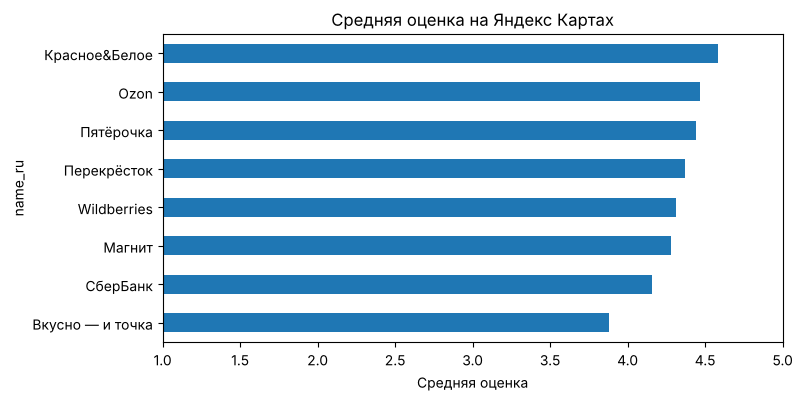

In [37]:
import matplotlib.pyplot as plt

brand_stats["mean"].sort_values().plot(kind="barh", figsize=(8, 4), title="Средняя оценка на Яндекс Картах")
plt.xlabel("Средняя оценка")
plt.xlim(1, 5)
plt.show()

- `kind="barh"` — горизонтальные столбики (`bar` — вертикальные);
- `figsize=(8, 4)` — размер картинки: ширина и высота;
- `plt.xlim(1, 5)` — шкала от 1 до 5, как шкала оценок.

---
# 10. Сохраняем результат

Таблица сохраняется одной командой `to_csv`. `index=False` — не сохранять номера строк отдельным столбцом.

Сохраним отзывы о выбранных брендах вместе с новыми столбцами:

In [38]:
df[df["name_ru"].isin(brands)][["name_ru", "city", "rubric", "rating", "words", "text"]].to_csv("brand_reviews.csv", index=False)
print("Файл сохранён")

Файл сохранён


Файл `brand_reviews.csv` появится в панели **Файлы** слева: правая кнопка мыши → **Скачать**. Его можно открыть в Excel или Google Таблицах.

---
# ★ 11. Если осталось время

## 11.1. Доля негативных отзывов по брендам

Средняя оценка хорошо показывает общую картину, но в PR часто важнее другое: **какая доля клиентов недовольна**. Средняя 4,4 может получиться и когда почти все ставят четвёрки, и когда большинство ставит пятёрки, а каждый десятый — единицу.

Создадим столбец «негативный отзыв»: условие `df["rating"] <= 2` даёт для каждой строки `True` или `False`.

In [39]:
df["negative"] = df["rating"] <= 2
df[["rating", "negative"]].head()

,rating,negative
0,4,False
1,5,False
2,5,False
3,5,False
4,4,False


Полезный приём: **среднее от столбца `True`/`False` — это доля `True`**. Python считает `True` как 1, а `False` как 0. Например, у `[True, False, False, True]` среднее равно 2 / 4 = 0,5 — половина.

Поэтому доля негативных отзывов по каждому бренду — это просто `mean()` после группировки:

In [40]:
negative_share = (df[df["name_ru"].isin(brands)]
                  .groupby("name_ru")["negative"]
                  .mean() * 100).round(1).sort_values(ascending=False)
negative_share

name_ru
Вкусно — и точка    19.2
СберБанк            18.2
Wildberries         12.3
Ozon                10.2
Перекрёсток         10.2
Магнит               9.4
Пятёрочка            7.1
Красное&Белое        5.4
Name: negative, dtype: float64

Получились проценты недовольных клиентов. Сравните с таблицей средних оценок из раздела 8.1 — порядок **не совпадает**:
- у Ozon средняя оценка одна из самых высоких (4,47), а доля недовольных — 10%, как у «Перекрёстка» и выше, чем у «Магнита»;
- у «Магнита» средняя ниже (4,28), но недовольных меньше — 9%.

Как так? Средняя складывается из всех оценок, а доля негатива — только из единиц и двоек. Разницу объяснит следующая таблица.

## 11.2. Сводная таблица: `crosstab`

`pd.crosstab` строит таблицу «что на что»: по строкам — значения одного столбца, по столбцам — другого, в ячейках — сколько раз они встретились вместе. Посмотрим, сколько каких оценок у каждого бренда:

In [41]:
brand_df = df[df["name_ru"].isin(brands)]
pd.crosstab(brand_df["name_ru"], brand_df["rating"])

rating,1,2,3,4,5
name_ru,,,,,
Ozon,5,1,3,2,48
Wildberries,7,1,4,6,47
Вкусно — и точка,6,4,7,8,27
Красное&Белое,3,1,2,12,56
Магнит,9,3,12,23,81
Перекрёсток,4,1,3,6,35
Пятёрочка,10,8,18,43,175
СберБанк,4,4,3,3,30


Абсолютные числа трудно сравнивать: у «Пятёрочки» отзывов в пять раз больше, чем у «Перекрёстка». Переведём в проценты внутри каждого бренда: `normalize="index"` — каждая строка в сумме даёт 100%.

In [42]:
(pd.crosstab(brand_df["name_ru"], brand_df["rating"], normalize="index") * 100).round(1)

rating,1,2,3,4,5
name_ru,,,,,
Ozon,8.5,1.7,5.1,3.4,81.4
Wildberries,10.8,1.5,6.2,9.2,72.3
Вкусно — и точка,11.5,7.7,13.5,15.4,51.9
Красное&Белое,4.1,1.4,2.7,16.2,75.7
Магнит,7.0,2.3,9.4,18.0,63.3
Перекрёсток,8.2,2.0,6.1,12.2,71.4
Пятёрочка,3.9,3.1,7.1,16.9,68.9
СберБанк,9.1,9.1,6.8,6.8,68.2


Так видно **распределение** оценок у каждого бренда. Это то, что в Excel называется сводной таблицей.

Теперь понятна загадка из 11.1: у Ozon оценки **поляризованы** — 81% пятёрок и почти 9% единиц, середины почти нет. А у «Магнита» много троек и четвёрок: клиенты не в восторге, но и не возмущены. Одна и та же средняя может скрывать очень разную картину — поэтому в PR-аналитике смотрят не только на среднее, но и на распределение.

## 11.3. Своя функция для каждой строки: `apply`

Иногда нужного метода в pandas нет, и проще написать свою функцию. `apply` применяет её к каждому значению столбца.

Разделим отзывы на короткие, средние и длинные. Сначала обычная функция — как `parse_card` в третьем семинаре:

In [43]:
def length_group(words):
    if words < 20:
        return "короткий"
    elif words < 60:
        return "средний"
    else:
        return "длинный"

print(length_group(10), length_group(35), length_group(120))

короткий средний длинный


Теперь применяем её ко всему столбцу `words`. Обратите внимание: в `apply` передаём **название функции без скобок** — pandas сам вызовет её для каждой строки.

In [44]:
df["length"] = df["words"].apply(length_group)
df["length"].value_counts()

length
средний     11058
короткий     4788
длинный      4108
Name: count, dtype: int64

И сразу проверим, связана ли длина отзыва с оценкой — с помощью приёма из раздела 11.1: доля негативных отзывов среди коротких, средних и длинных.

In [45]:
(df.groupby("length")["negative"].mean() * 100).round(1)

length
длинный     23.9
короткий     3.2
средний      6.8
Name: negative, dtype: float64

Среди длинных отзывов негативных заметно больше, чем среди коротких. Это то же наблюдение, что и в разделе 8 («недовольные пишут длиннее»), только сформулированное как доля.

---
# Итоги

| Что сделать | Python (семинар 2) | Pandas |
|---|---|---|
| Загрузить таблицу | `open` + цикл + `split` | `pd.read_csv("файл.csv")` |
| Посмотреть на данные | `print(lines[:5])` | `df.head()`, `df.info()`, `df.sample(5)` |
| Средняя | `sum(grades) / len(grades)` | `df["rating"].mean()` |
| Частоты | `Counter(grades)` | `df["rating"].value_counts()` |
| Отобрать строки | цикл + `if` + `append` | `df[df["rating"] == 1]` |
| Несколько условий | `and`, `or` | `&`, `\|` + скобки вокруг условий |
| Сортировка | — | `df.sort_values("столбец")` |
| Пропуски | — | `df.isna().sum()`, `df.dropna(subset=[...])` |
| Новый столбец | — | `df["новый"] = ...` |
| Текст в столбце | цикл + методы строк | `df["text"].str.lower()`, `.str.contains(...)`, `.str.split(...)` |
| Среднее по группам | несколько списков + цикл | `df.groupby("столбец")["rating"].mean()` |
| Несколько показателей | — | `.agg(["count", "mean"])` |
| Сохранить | `csv.writer` | `df.to_csv("файл.csv", index=False)` |
| ★ Доля строк с условием | счётчик в цикле | `(df["rating"] <= 2).mean()` |
| ★ Сводная таблица | — | `pd.crosstab(df["столбец1"], df["столбец2"])` |
| ★ Своя функция для каждой строки | цикл | `df["столбец"].apply(функция)` |

**Главное правило:** команды pandas не меняют таблицу сами — чтобы сохранить результат, пишите `df = ...` или `df["новый столбец"] = ...`.